# U4 · Práctica sobre clasificación, asociación y agrupación de clientes
## Introducción paso a paso con Wholesale Customers
**Objetivo:** comprender qué pregunta responde cada técnica y aplicar ejemplos sencillos en Python desde una nueva fuente:
UCI Machine Learning Repository

https://archive.ics.uci.edu/

Especificamente para esta práctica se utiliza un dataset de Wholesale Customers.


Cada fila representa un cliente; las seis variables de gasto son importes anuales en unidades monetarias. No son facturas individuales. Fuente: Cardoso, M. (2013), UCI, DOI: https://doi.org/10.24432/C5030X. Licencia CC BY 4.0.

**Recorrido:** datos → correlación → asociación → clustering → LDA → red bayesiana.

| Técnica | Pregunta | Tipo |
|---|---|---|
| Correlación | ¿Cómo varían juntas dos variables? | Exploración estadística |
| Asociación | ¿Qué condiciones aparecen juntas? | No supervisado |
| Clustering | ¿Qué clientes son semejantes? | No supervisado |
| LDA | ¿A qué canal comercial pertenece un cliente? | Supervisado |
| Red bayesiana | ¿Cómo cambia una probabilidad al observar evidencia? | Modelo probabilístico |

**Clasificar** requiere clases conocidas.

**Agrupar** descubre segmentos sin usar esas clases. 


Los números de cluster no equivalen a las clases comerciales.


## 0. Preparación en VS Code
Selecciona el intérprete/kernel de tu entorno `.venv`. Si necesitas crearlo:

| Paso | macOS | Windows (PowerShell) |
|---|---|---|
| Crear entorno | `python3 -m venv .venv` | `py -m venv .venv` |
| Activar | `source .venv/bin/activate` | `.venv\Scripts\Activate.ps1` |
| Instalar | `python -m pip install pandas numpy matplotlib scikit-learn ipykernel` | Mismo comando |



Ejecuta las celdas en orden. La primera carga requiere internet; después se reutiliza la copia local. Para instalar desde el kernel, descomenta la siguiente línea.


In [17]:
# %pip install pandas numpy matplotlib scikit-learn ipykernel

In [18]:
from pathlib import Path
from urllib.request import urlopen
from io import BytesIO
from zipfile import ZipFile
from itertools import permutations
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from IPython.display import display

print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__, '| numpy:', np.__version__, '| scikit-learn:', sklearn.__version__)
plt.rcParams['figure.figsize'] = (9, 5)


Python: 3.12.0
pandas: 3.0.6 | numpy: 2.5.3 | scikit-learn: 1.9.1


## 1. Cargar los datos desde Python
Descargamos el ZIP oficial de UCI y leemos su CSV con pandas. El archivo se conserva en `data/raw` dentro de la carpeta desde la que se ejecuta el notebook.

El CSV incluye `Channel` y `Region`. Aunque UCI asigna roles propios a estas columnas, aquí **elegimos Channel como objetivo de clasificación**. En clustering no utilizaremos ninguna de las dos.


In [19]:
carpeta_raw = Path('../data/raw')
carpeta_raw.mkdir(parents=True, exist_ok=True)
archivo_csv = carpeta_raw / 'wholesale_customers.csv'
url = 'https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip'

if not archivo_csv.exists():
    with urlopen(url, timeout=60) as respuesta:
        contenido_zip = respuesta.read()
    with ZipFile(BytesIO(contenido_zip)) as comprimido:
        nombre_csv = next(nombre for nombre in comprimido.namelist() if nombre.lower().endswith('.csv'))
        archivo_csv.write_bytes(comprimido.read(nombre_csv))

datos = pd.read_csv(archivo_csv)
print('Filas y columnas:', datos.shape)
display(datos.head())


Filas y columnas: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


### Diccionario de variables
| Columna | Significado |
|---|---|
| Fresh | Gasto en productos frescos |
| Milk | Gasto en productos lácteos |
| Grocery | Gasto en abarrotes |
| Frozen | Gasto en congelados |
| Detergents_Paper | Gasto en detergentes y papel |
| Delicassen | Gasto en delicatessen (así se escribe en el CSV) |
| Channel | 1: hoteles/restaurantes/cafeterías; 2: minoristas |
| Region | 1: Lisboa; 2: Oporto; 3: otras regiones |

Las categorías codificadas con números no son cantidades. Calcular una correlación de Pearson con esos códigos puede inducir interpretaciones erróneas.


In [20]:
columnas_gasto = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
nombres_canal = {1: 'Hoteles/restaurantes/cafeterías', 2: 'Minoristas'}
display(datos.dtypes.to_frame('tipo'))
display(datos.isna().sum().to_frame('faltantes'))
display(datos[columnas_gasto].describe().round(2))
print('Filas idénticas:', datos.duplicated().sum())
# Dos clientes podrían tener los mismos valores: no borrar duplicados automáticamente.
display(datos['Channel'].map(nombres_canal).value_counts().to_frame('clientes'))


,tipo
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


,faltantes
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,12000.30,5796.27,7951.28,3071.93,2881.49,1524.87
std,12647.33,7380.38,9503.16,4854.67,4767.85,2820.11
min,3.00,55.00,3.00,25.00,3.00,3.00
25%,3127.75,1533.00,2153.00,742.25,256.75,408.25
50%,8504.00,3627.00,4755.50,1526.00,816.50,965.50
75%,16933.75,7190.25,10655.75,3554.25,3922.00,1820.25
max,112151.00,73498.00,92780.00,60869.00,40827.00,47943.00


Filas idénticas: 0


,clientes
Channel,
Hoteles/restaurantes/cafeterías,298
Minoristas,142


## Correlación en dos dimensiones
Cada punto del diagrama representa un cliente: X es gasto en leche y Y es gasto en abarrotes.

Pearson mide relación **lineal**: −1 indica relación negativa perfecta; +1, positiva perfecta; cerca de 0, escasa relación lineal. No demuestra causalidad ni es un porcentaje de probabilidad. Los valores atípicos influyen y una relación curva puede tener Pearson cercano a cero.


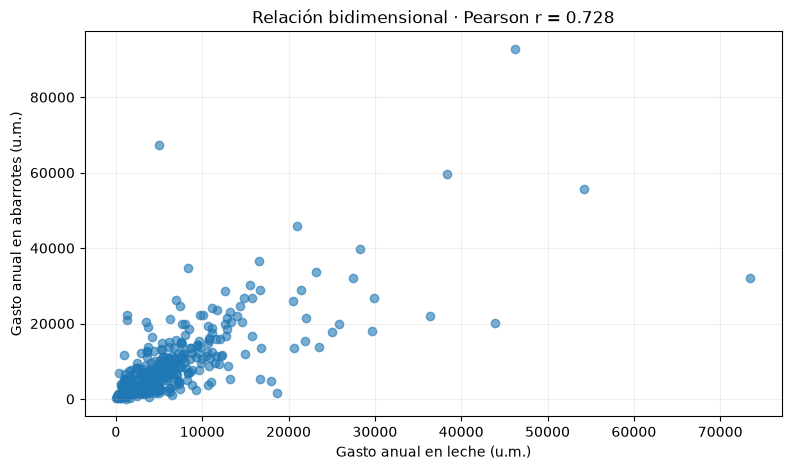

In [21]:
r = datos['Milk'].corr(datos['Grocery'])
plt.scatter(datos['Milk'], datos['Grocery'], alpha=0.6)
plt.xlabel('Gasto anual en leche (u.m.)')
plt.ylabel('Gasto anual en abarrotes (u.m.)')
plt.title(f'Relación bidimensional · Pearson r = {r:.3f}')
plt.grid(alpha=0.2)
plt.show()


La matriz de correlación compara todos los pares de variables de gasto. La diagonal vale 1 porque cada variable se compara consigo misma. Spearman usa rangos y permite explorar relaciones monótonas, aunque no sean lineales.


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.000,0.101,-0.012,0.346,-0.102,0.245
Milk,0.101,1.000,0.728,0.124,0.662,0.406
Grocery,-0.012,0.728,1.000,-0.040,0.925,0.205
Frozen,0.346,0.124,-0.040,1.000,-0.132,0.391
Detergents_Paper,-0.102,0.662,0.925,-0.132,1.000,0.069
Delicassen,0.245,0.406,0.205,0.391,0.069,1.000


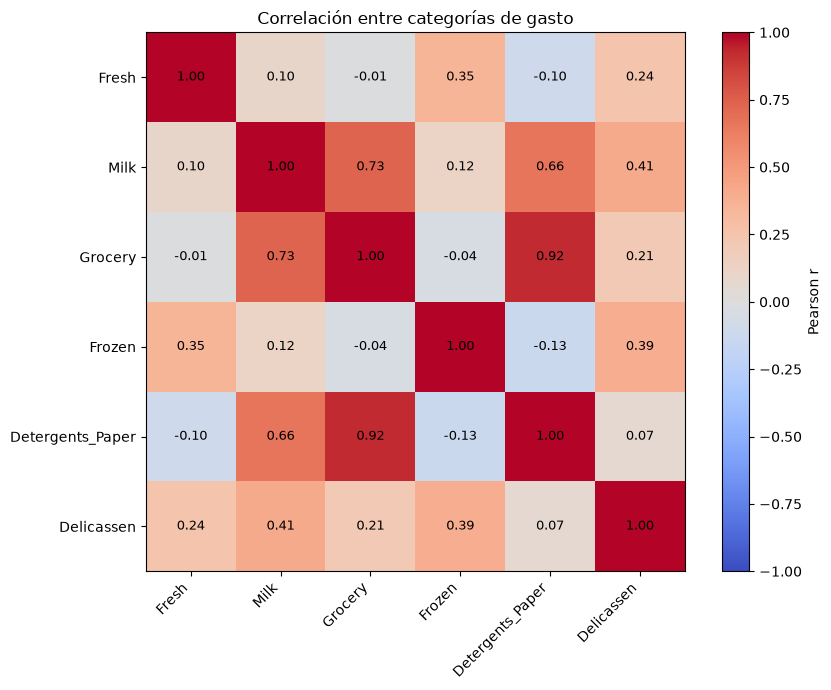

Spearman leche–abarrotes: 0.773


In [22]:
correlaciones = datos[columnas_gasto].corr(method='pearson')
display(correlaciones.round(3))
fig, ax = plt.subplots(figsize=(9, 7))
imagen = ax.imshow(correlaciones, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(columnas_gasto)), columnas_gasto, rotation=45, ha='right')
ax.set_yticks(range(len(columnas_gasto)), columnas_gasto)
for fila in range(len(columnas_gasto)):
    for columna in range(len(columnas_gasto)):
        ax.text(columna, fila, f'{correlaciones.iloc[fila, columna]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(imagen, ax=ax, label='Pearson r')
ax.set_title('Correlación entre categorías de gasto')
plt.tight_layout()
plt.show()
print('Spearman leche–abarrotes:', round(datos['Milk'].corr(datos['Grocery'], method='spearman'), 3))


**Para interpretar:** ¿qué pares presentan mayor relación positiva? ¿Podría el tamaño del negocio explicar parte de la relación? No concluir que una categoría provoca el gasto en otra.


## Reglas de asociación: perfiles anuales
Una regla A → B describe la aparición conjunta de condiciones. Aquí A puede ser “gasto alto en leche” y B “gasto alto en abarrotes”. **No implica que ambos productos se compraron en la misma factura.**

Definimos “alto” como gasto mayor que la mediana de la categoría; es una decisión didáctica relativa a este dataset.

- Soporte = P(A y B).
- Confianza = P(B | A) = P(A y B) / P(A).
- Lift = P(B | A) / P(B).

Lift > 1: asociación positiva; = 1: independencia en las frecuencias; < 1: asociación negativa. La regla no demuestra causalidad. A → B y B → A pueden tener distinta confianza.


In [23]:
umbrales = datos[columnas_gasto].median()
eventos = datos[columnas_gasto].gt(umbrales, axis='columns')
display(umbrales.to_frame('mediana: umbral de gasto alto'))
display(eventos.head())


,mediana: umbral de gasto alto
Fresh,8504.0
Milk,3627.0
Grocery,4755.5
Frozen,1526.0
Detergents_Paper,816.5
Delicassen,965.5


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,True,True,True,False,True,True
1,False,True,True,True,True,True
2,False,True,True,True,True,True
3,True,False,False,True,False,True
4,True,True,True,True,True,True


Calculamos una regla a mano antes de generar todas. El promedio de una serie booleana equivale a la proporción de valores verdaderos.


In [24]:
A = eventos['Milk']
B = eventos['Grocery']
p_A = A.mean()
p_B = B.mean()
soporte = (A & B).mean()
confianza = soporte / p_A
lift = confianza / p_B
print('Regla: leche alta → abarrotes altos')
print(f'Soporte: {soporte:.3f}; confianza: {confianza:.3f}; lift: {lift:.3f}')


Regla: leche alta → abarrotes altos
Soporte: 0.418; confianza: 0.836; lift: 1.673


In [25]:
registros_reglas = []
for antecedente, consecuente in permutations(columnas_gasto, 2):
    A = eventos[antecedente]
    B = eventos[consecuente]
    soporte = (A & B).mean()
    confianza = soporte / A.mean() if A.mean() > 0 else np.nan
    lift = confianza / B.mean() if B.mean() > 0 else np.nan
    registros_reglas.append({'antecedente_alto': antecedente, 'consecuente_alto': consecuente,
                            'soporte': soporte, 'confianza': confianza, 'lift': lift})
reglas = pd.DataFrame(registros_reglas)
reglas_interes = reglas.loc[(reglas['soporte'] >= 0.20) & (reglas['confianza'] >= 0.70) & (reglas['lift'] > 1)]
display(reglas_interes.sort_values('lift', ascending=False).round(3))


,antecedente_alto,consecuente_alto,soporte,confianza,lift
6,Milk,Grocery,0.418,0.836,1.673
11,Grocery,Milk,0.418,0.836,1.673
13,Grocery,Detergents_Paper,0.411,0.823,1.645
22,Detergents_Paper,Grocery,0.411,0.823,1.645
8,Milk,Detergents_Paper,0.391,0.782,1.564
21,Detergents_Paper,Milk,0.391,0.782,1.564


Los umbrales 0.20 y 0.70 son ilustrativos, no estándares universales. Este cálculo exhaustivo considera únicamente reglas de una condición hacia otra; **no implementa Apriori ni FP-Growth**, que permiten buscar conjuntos frecuentes más amplios. Para canastas reales necesitaríamos datos por factura, como Online Retail de UCI.


## Clustering como segmentación
Usaremos únicamente los seis gastos: no existe una variable `y` de clase para entrenar K-means.

K-means alterna asignación al centro más cercano y actualización de centros para reducir las distancias cuadradas dentro de los grupos. Hay que elegir K.

### Preparación de las distancias
Los gastos presentan asimetría y escalas diferentes. `log1p(x)` calcula log(1+x), comprime diferencias grandes y admite ceros. Luego `StandardScaler` centra y escala cada variable.

Estas decisiones cambian lo que consideramos semejante. Los gastos originales se conservan para interpretar los perfiles. No eliminaremos automáticamente clientes con gasto elevado.


In [26]:
X_gastos = datos[columnas_gasto].copy()
X_log = np.log1p(X_gastos)
escalador_clusters = StandardScaler()
X_escalado = escalador_clusters.fit_transform(X_log)
display(pd.DataFrame(X_escalado, columns=columnas_gasto).head().round(3))


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.486,0.976,0.440,-1.509,0.644,0.409
1,0.088,0.991,0.652,0.134,0.766,0.628
2,0.016,0.891,0.455,0.377,0.804,1.777
3,0.517,-0.958,-0.085,1.142,-0.329,0.633
4,0.881,0.440,0.396,0.757,0.405,1.457


### Comparar varios valores de K
La inercia disminuye al aumentar K; por sí sola no basta para elegirlo. La silueta compara cercanía al propio grupo y separación respecto a otros: toma valores entre −1 y 1. Se combina con interpretabilidad y estabilidad; no garantiza segmentos comerciales útiles.


,k,inercia,silueta
0,2,1844.064,0.290
1,3,1553.413,0.258
2,4,1386.863,0.188
3,5,1266.149,0.192
4,6,1174.536,0.195


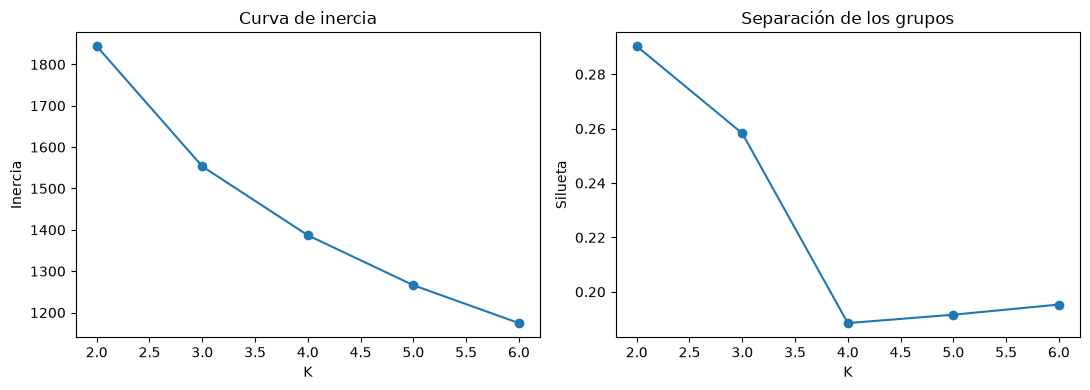

In [27]:
resultados_k = []
for k in range(2, 7):
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=20)
    etiquetas_k = modelo_k.fit_predict(X_escalado)
    resultados_k.append({'k': k, 'inercia': modelo_k.inertia_,
                         'silueta': silhouette_score(X_escalado, etiquetas_k)})
evaluacion_k = pd.DataFrame(resultados_k)
display(evaluacion_k.round(3))
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(evaluacion_k['k'], evaluacion_k['inercia'], 'o-')
ejes[0].set(xlabel='K', ylabel='Inercia', title='Curva de inercia')
ejes[1].plot(evaluacion_k['k'], evaluacion_k['silueta'], 'o-')
ejes[1].set(xlabel='K', ylabel='Silueta', title='Separación de los grupos')
plt.tight_layout()
plt.show()


Silueta: 0.258


,clientes
cluster,
0,145
1,212
2,83


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,12205.0,7209.0,9965.0,2033.0,3378.0,2005.0
1,9635.0,1598.5,2151.0,2151.0,274.5,686.0
2,1531.0,6154.0,10487.0,398.0,4196.0,490.0


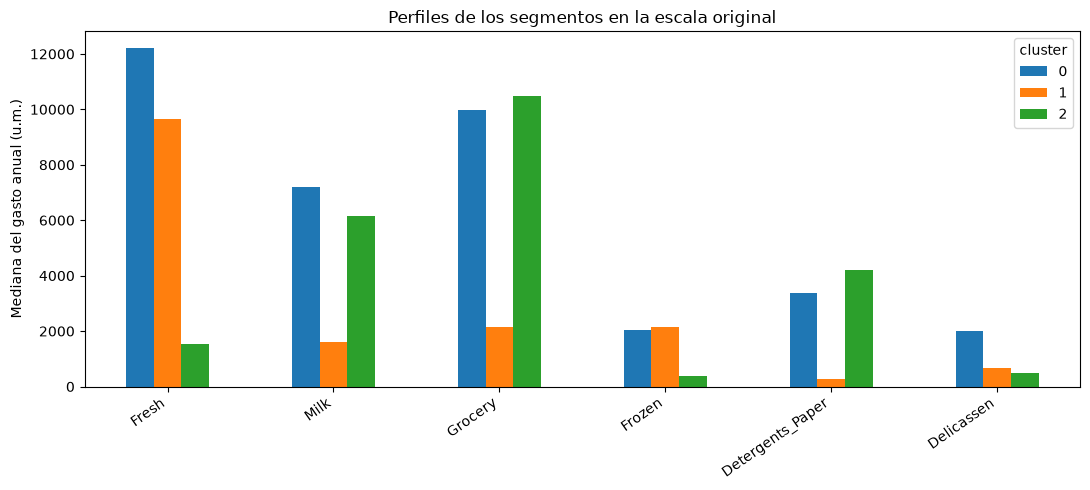

In [28]:
# Tres grupos para explorar perfiles; no afirmamos que sea el K óptimo.
k_elegido = 3
modelo_clusters = KMeans(n_clusters=k_elegido, random_state=42, n_init=20)
segmentos = datos.copy()
segmentos['cluster'] = modelo_clusters.fit_predict(X_escalado)
print('Silueta:', round(silhouette_score(X_escalado, segmentos['cluster']), 3))
display(segmentos['cluster'].value_counts().sort_index().to_frame('clientes'))
perfiles = segmentos.groupby('cluster')[columnas_gasto].median()
display(perfiles.round(2))
perfiles.T.plot(kind='bar', figsize=(11, 5))
plt.ylabel('Mediana del gasto anual (u.m.)')
plt.title('Perfiles de los segmentos en la escala original')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()


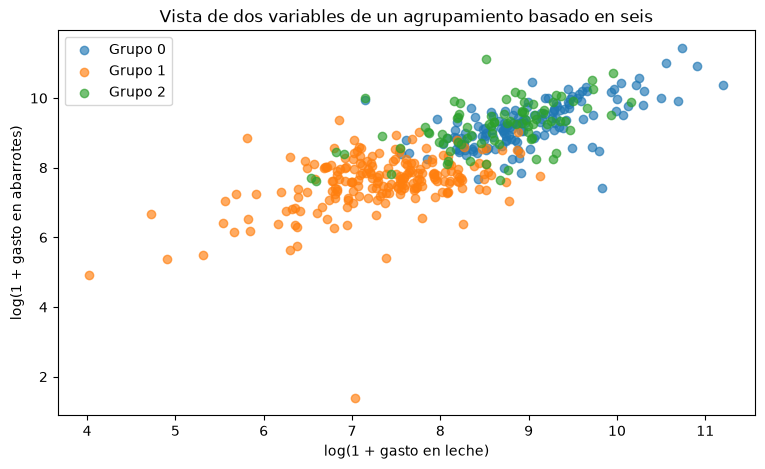

Channel,Hoteles/restaurantes/cafeterías,Minoristas
cluster,,
0,0.386,0.614
1,0.986,0.014
2,0.398,0.602


In [29]:
for grupo in sorted(segmentos['cluster'].unique()):
    clientes_grupo = segmentos.loc[segmentos['cluster'] == grupo]
    plt.scatter(np.log1p(clientes_grupo['Milk']), np.log1p(clientes_grupo['Grocery']),
                label=f'Grupo {grupo}', alpha=0.65)
plt.xlabel('log(1 + gasto en leche)')
plt.ylabel('log(1 + gasto en abarrotes)')
plt.title('Vista de dos variables de un agrupamiento basado en seis')
plt.legend()
plt.show()
# Channel se consulta DESPUÉS de entrenar; no participó en las distancias.
display(pd.crosstab(segmentos['cluster'], segmentos['Channel'].map(nombres_canal), normalize='index').round(3))


**Interpretación:** describe cada segmento con sus medianas, no solamente con el número asignado. Los IDs pueden cambiar entre ejecuciones/configuraciones. La gráfica muestra dos de las seis variables: cierto solapamiento visual no significa que el algoritmo haya usado únicamente esas dos. No comparar IDs de clusters directamente con los códigos de Channel.


## Análisis discriminante lineal (LDA)
Ahora la pregunta cambia: ¿podemos predecir el canal conocido a partir de los gastos?

LDA es **supervisado**. Busca combinaciones lineales que separen clases considerando la variación dentro de ellas. Su modelo clásico supone distribuciones normales multivariadas por clase y covarianza compartida. Los datos reales pueden incumplir estos supuestos; la evaluación es necesaria.

Separaremos entrenamiento y prueba. Usamos los logaritmos, pero el escalador se ajusta **solo al entrenamiento**, dentro de un pipeline. La prueba se conserva para medir generalización. Channel no se incluye en X; Region tampoco se utilizará en esta introducción.


In [30]:
X_clasificacion = X_log.copy()
y_canal = datos['Channel'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X_clasificacion, y_canal, test_size=0.25, random_state=42, stratify=y_canal)
modelo_lda = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis())
modelo_lda.fit(X_train, y_train)
predicciones_lda = modelo_lda.predict(X_test)
print('Clientes de entrenamiento:', len(X_train), '| prueba:', len(X_test))
print('Exactitud LDA:', round(accuracy_score(y_test, predicciones_lda), 3))
clase_mayoritaria = y_train.mode().iloc[0]
baseline = np.full(len(y_test), clase_mayoritaria)
print('Exactitud de predecir siempre la clase mayoritaria:', round(accuracy_score(y_test, baseline), 3))
print(classification_report(y_test, predicciones_lda, labels=[1, 2],
      target_names=[nombres_canal[1], nombres_canal[2]], zero_division=0))


Clientes de entrenamiento: 330 | prueba: 110
Exactitud LDA: 0.945
Exactitud de predecir siempre la clase mayoritaria: 0.682
                                 precision    recall  f1-score   support

Hoteles/restaurantes/cafeterías       0.96      0.96      0.96        75
                     Minoristas       0.91      0.91      0.91        35

                       accuracy                           0.95       110
                      macro avg       0.94      0.94      0.94       110
                   weighted avg       0.95      0.95      0.95       110



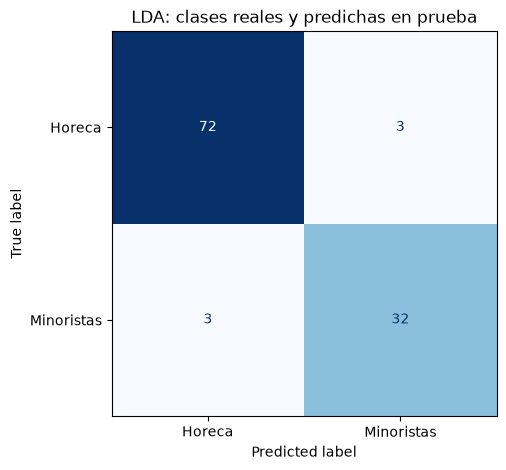

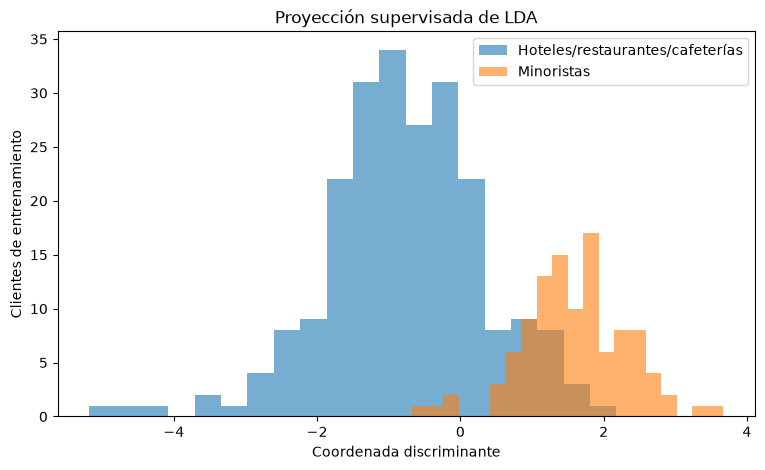

In [31]:
ConfusionMatrixDisplay.from_predictions(y_test, predicciones_lda, labels=[1, 2],
    display_labels=['Horeca', 'Minoristas'], cmap='Blues', colorbar=False)
plt.title('LDA: clases reales y predichas en prueba')
plt.show()
proyeccion_train = modelo_lda.transform(X_train).ravel()
for clase in [1, 2]:
    plt.hist(proyeccion_train[y_train.to_numpy() == clase], bins=20, alpha=0.6,
             label=nombres_canal[clase])
plt.xlabel('Coordenada discriminante')
plt.ylabel('Clientes de entrenamiento')
plt.title('Proyección supervisada de LDA')
plt.legend()
plt.show()


Con dos clases, LDA tiene como máximo una dimensión discriminante. Esta gráfica muestra cómo una combinación de los seis gastos separa clases conocidas. No equivale a descubrir clases nuevas.

**Métricas:** exactitud = proporción total de aciertos; precisión por clase = aciertos entre las predicciones de esa clase; recall = aciertos entre los casos reales de esa clase. La diagonal de la matriz contiene aciertos. Una única partición sirve para introducir el tema; un estudio más sólido requeriría validación cruzada y revisar supuestos.


## Red bayesiana pequeña y apoyo a decisiones
Una red bayesiana contiene variables, dependencias en un grafo dirigido sin ciclos y tablas de probabilidades condicionales.

Usaremos una estructura **propuesta como ejemplo**, no descubierta automáticamente:

- `Channel` → `Milk_alto`
- `Channel` → `Grocery_alto`

Esta estructura supone independencia condicional entre los dos eventos de gasto dado Channel. Es una red tipo **Naive Bayes**; el supuesto puede ser imperfecto. Las flechas representan la factorización probabilística y no prueban causalidad.

La distribución conjunta es:

P(C, M, G) = P(C) × P(M | C) × P(G | C).

Construiremos tablas con entrenamiento y consultaremos P(Channel | evidencia). Para una red tan pequeña podemos hacer inferencia explícita, sin instalar otra biblioteca.


In [32]:
# Recuperar gastos originales de los clientes de entrenamiento.
gastos_train = datos.loc[X_train.index, ['Milk', 'Grocery']].copy()
gastos_test = datos.loc[X_test.index, ['Milk', 'Grocery']].copy()
# Umbrales aprendidos únicamente del entrenamiento.
umbrales_bn = gastos_train.median()
eventos_train = gastos_train.gt(umbrales_bn, axis='columns')
eventos_test = gastos_test.gt(umbrales_bn, axis='columns')
print('Umbrales de la red:')
display(umbrales_bn.to_frame('mediana de entrenamiento'))


Umbrales de la red:


,mediana de entrenamiento
Milk,3664.0
Grocery,5015.5


Usamos suavizado de Laplace: sumamos 1 al conteo de cada estado. Evita probabilidades cero por ausencia de ejemplos. Channel y cada evento tienen dos estados. Se muestran las probabilidades de gasto alto; gasto no alto tiene probabilidad complementaria.


In [33]:
conteos_canal = y_train.value_counts().reindex([1, 2], fill_value=0)
prior_canal = (conteos_canal + 1) / (len(y_train) + 2)
prob_alto_dado_canal = pd.DataFrame(index=[1, 2], columns=['Milk', 'Grocery'], dtype=float)
for canal in [1, 2]:
    filas_canal = y_train == canal
    total_canal = filas_canal.sum()
    for categoria in ['Milk', 'Grocery']:
        conteo_alto = eventos_train.loc[filas_canal, categoria].sum()
        prob_alto_dado_canal.loc[canal, categoria] = (conteo_alto + 1) / (total_canal + 2)
display(prior_canal.to_frame('P(Channel)'))
display(prob_alto_dado_canal.rename(columns={'Milk': 'P(Milk alto | Channel)',
                                         'Grocery': 'P(Grocery alto | Channel)'}).round(4))


,P(Channel)
Channel,
1,0.674699
2,0.325301


,P(Milk alto | Channel),P(Grocery alto | Channel)
1,0.3111,0.2800
2,0.8899,0.9541


### Inferencia con evidencia
Calculamos P(C) × P(M alto | C) × P(G alto | C) para cada canal y normalizamos dividiendo entre la suma. Es Bayes aplicado a la distribución conjunta del modelo. Las probabilidades obtenidas dependen de los datos y del supuesto de independencia.


,sin_evidencia,ambos_gastos_altos
Channel,,
Hoteles/restaurantes/cafeterías,0.6747,0.1755
Minoristas,0.3253,0.8245


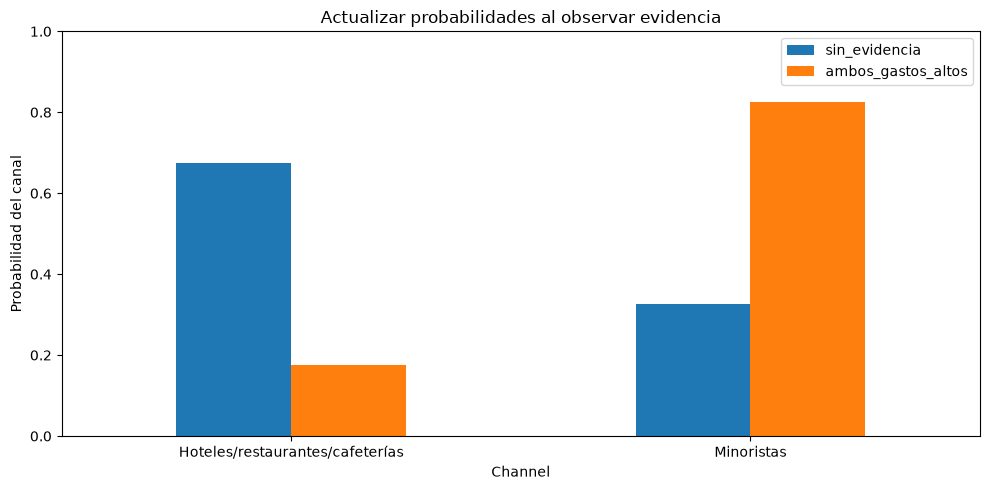

In [34]:
pesos_evidencia = prior_canal * prob_alto_dado_canal['Milk'] * prob_alto_dado_canal['Grocery']
posterior_canal = pesos_evidencia / pesos_evidencia.sum()
comparacion_bn = pd.DataFrame({'sin_evidencia': prior_canal, 'ambos_gastos_altos': posterior_canal})
comparacion_bn.index = comparacion_bn.index.map(nombres_canal)
display(comparacion_bn.round(4))
comparacion_bn.plot(kind='bar', ylim=(0, 1), figsize=(10, 5))
plt.ylabel('Probabilidad del canal')
plt.title('Actualizar probabilidades al observar evidencia')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Evaluación básica de la red como clasificador
Para cada cliente de prueba usamos la probabilidad de cada evento observado (alto o no alto), calculamos ambos pesos y los normalizamos. Tomamos el canal de mayor probabilidad. Este ejemplo usa dos variables discretizadas, mientras LDA usa seis continuas: no es una comparación controlada de algoritmos.


In [35]:
pesos_prueba = pd.DataFrame(index=X_test.index, columns=[1, 2], dtype=float)
for canal in [1, 2]:
    peso = pd.Series(prior_canal.loc[canal], index=X_test.index)
    for categoria in ['Milk', 'Grocery']:
        p_alto = prob_alto_dado_canal.loc[canal, categoria]
        probabilidades_evento = np.where(eventos_test[categoria], p_alto, 1 - p_alto)
        peso = peso * probabilidades_evento
    pesos_prueba[canal] = peso
posteriores_prueba = pesos_prueba.div(pesos_prueba.sum(axis=1), axis='index')
predicciones_bn = posteriores_prueba.idxmax(axis=1)
print('Exactitud de la red pequeña:', round(accuracy_score(y_test, predicciones_bn), 3))
display(posteriores_prueba.head().round(4))


Exactitud de la red pequeña: 0.9


,1,2
111,0.1755,0.8245
237,0.9192,0.0808
271,0.9192,0.0808
219,0.9951,0.0049
142,0.1755,0.8245


### ¿Cómo apoya una decisión?
La red estima probabilidades; decidir requiere además costos, beneficios y restricciones. Podría ayudar a priorizar qué oferta revisar, pero no garantiza una respuesta del cliente ni permite estimar el efecto de una promoción. Eso requeriría variables y evidencia adicionales.

Una red bayesiana general puede tener otras estructuras, aprenderse con datos o definirse con expertos. Este notebook introduce un caso pequeño; no realiza descubrimiento causal ni optimización de decisiones.


## 4. Guardar resultados
Se conserva la tabla original junto con el segmento asignado, las reglas encontradas y la evaluación de K. El número de cluster no es una etiqueta comercial universal.


In [36]:
carpeta_processed = Path('../data/processed')
carpeta_processed.mkdir(parents=True, exist_ok=True)
segmentos.to_csv(carpeta_processed / 'clientes_segmentados.csv', index=False)
reglas.to_csv(carpeta_processed / 'reglas_perfiles_anuales.csv', index=False)
evaluacion_k.to_csv(carpeta_processed / 'evaluacion_k.csv', index=False)
print('Resultados guardados en:', carpeta_processed.resolve())


Resultados guardados en: /Users/lizette/Coding/bigdata/U4_1_clustering/data/processed


## 5. Actividad de cierre
1. Explica la diferencia entre clasificar y agrupar usando esta práctica.
2. Describe una correlación sin atribuir causalidad.
3. Interpreta soporte, confianza y lift de una regla encontrada.
4. Describe los tres segmentos con sus medianas y propone nombres.
5. Cambia K y explica qué sucede con silueta y perfiles.
6. Explica por qué Channel se excluyó de clustering y se utilizó como objetivo en LDA.
7. Identifica un error de LDA en la matriz de confusión.
8. Compara la probabilidad del canal antes y después de observar evidencia en la red.
9. Explica por qué las reglas de este dataset no son reglas de canastas de compra.

## Fuentes y alcance
- Dataset: https://archive.ics.uci.edu/dataset/292/wholesale+customers
- Pearson: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html
- Métricas de asociación: https://rasbt.github.io/mlxtend/api_modules/mlxtend.frequent_patterns/association_rules/
- Clustering: https://scikit-learn.org/stable/modules/clustering.html
- LDA: https://scikit-learn.org/stable/modules/lda_qda.html
- Redes bayesianas: https://pgmpy.org/started/quickstart.html
- Transacciones para una práctica posterior: https://archive.ics.uci.edu/dataset/352/online+retail

Los parámetros y umbrales se eligen con fines didácticos. No se presentan los grupos como categorías verdaderas ni las probabilidades como certezas. Semilla 42 para repetir las particiones e inicializaciones dentro de una configuración compatible; las versiones de bibliotecas se muestran al inicio.
